In [ ]:
import os, random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model
from google.colab import drive
from sklearn.model_selection import train_test_split

drive.mount("/content/drive")

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

def set_seeds(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seeds(42)

Mounted at /content/drive
TensorFlow: 2.21.0
GPU: []


In [ ]:
DATA_ROOT = "/content/drive/MyDrive/acne clean pigmentation wrinkles"
CSV_PATH  = os.path.join(DATA_ROOT, "labels.csv")

IMG_SIZE  = (224, 224)
BATCH_SIZE = 32
CLASSES = ["acne", "pigmentation", "wrinkles"]
NUM_CLASSES = len(CLASSES)

EPOCHS = 25
LR = 1e-3

STUDENT_SAVE_PATH = os.path.join(DATA_ROOT, "mobilevit_student_baseline.keras")

print("DATA_ROOT:", DATA_ROOT)
print("CSV_PATH :", CSV_PATH)
print("Saving to:", STUDENT_SAVE_PATH)

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(f"labels.csv not found at: {CSV_PATH}")

DATA_ROOT: /content/drive/MyDrive/acne clean pigmentation wrinkles
CSV_PATH : /content/drive/MyDrive/acne clean pigmentation wrinkles/labels.csv
Saving to: /content/drive/MyDrive/acne clean pigmentation wrinkles/mobilevit_student_baseline.keras


In [ ]:
df = pd.read_csv(CSV_PATH)

required_cols = ["filename"] + CLASSES
missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns in labels.csv: {missing}")

df["filename"] = df["filename"].astype(str).apply(lambda x: os.path.join(DATA_ROOT, x))

# Drop missing files (safety)
exists_mask = df["filename"].apply(os.path.exists)
if exists_mask.mean() < 1.0:
    print(f"⚠️ Dropping {(~exists_mask).sum()} rows with missing image files.")
df = df[exists_mask].reset_index(drop=True)

print("Total usable samples:", len(df))
print(df.head())


Total usable samples: 5062
                                            filename  acne  wrinkles  \
0  /content/drive/MyDrive/acne clean pigmentation...     1         0   
1  /content/drive/MyDrive/acne clean pigmentation...     1         0   
2  /content/drive/MyDrive/acne clean pigmentation...     1         0   
3  /content/drive/MyDrive/acne clean pigmentation...     1         0   
4  /content/drive/MyDrive/acne clean pigmentation...     1         0   

   pigmentation  clean  
0             0      0  
1             0      0  
2             0      0  
3             0      0  
4             0      0  


In [ ]:
df["_stratify_key"] = df[CLASSES].astype(int).astype(str).agg("".join, axis=1)

train_val_df, test_df = train_test_split(
    df, test_size=0.15, random_state=42, stratify=df["_stratify_key"]
)

train_df, val_df = train_test_split(
    train_val_df, test_size=0.15, random_state=42, stratify=train_val_df["_stratify_key"]
)

for d in (train_df, val_df, test_df):
    d.drop(columns=["_stratify_key"], inplace=True)

print("Train:", len(train_df), "Val:", len(val_df), "Test:", len(test_df))

Train: 3656 Val: 646 Test: 760


In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
], name="data_augmentation")

def decode_and_resize(path):
    img_bytes = tf.io.read_file(path)
    img = tf.io.decode_image(img_bytes, channels=3, expand_animations=False)  # jpg/png
    img = tf.image.convert_image_dtype(img, tf.float32)  # [0,1]
    img = tf.image.resize(img, IMG_SIZE)
    img.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    return img

def parse_function(filename, labels):
    image = decode_and_resize(filename)
    labels = tf.cast(labels, tf.float32)
    return image, labels

def make_dataset(frame: pd.DataFrame, batch_size: int, augment: bool):
    filenames = frame["filename"].values
    labels = frame[CLASSES].values.astype(np.float32)

    ds = tf.data.Dataset.from_tensor_slices((filenames, labels))
    ds = ds.shuffle(buffer_size=min(len(frame), 4096), seed=42, reshuffle_each_iteration=True)
    ds = ds.map(parse_function, num_parallel_calls=tf.data.AUTOTUNE)

    if augment:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, BATCH_SIZE, augment=True)
val_ds   = make_dataset(val_df,   BATCH_SIZE, augment=False)
test_ds  = make_dataset(test_df,  BATCH_SIZE, augment=False)

In [ ]:
# ============================================================
# 5) MobileViT Student (KD-compatible, no dynamic layer creation)
# ============================================================
import tensorflow as tf
from tensorflow.keras import layers, Model

class ConvBNAct(layers.Layer):
    def __init__(self, filters, kernel=3, stride=1, act=True, name_prefix="cba"):
        super().__init__(name=name_prefix)
        self.conv = layers.Conv2D(filters, kernel, stride, padding="same", use_bias=False)
        self.bn = layers.BatchNormalization()
        self.act = layers.Activation("swish") if act else None

    def call(self, x, training=False):
        x = self.conv(x)
        x = self.bn(x, training=training)
        if self.act is not None:
            x = self.act(x)
        return x

class InvertedResidual(layers.Layer):
    def __init__(self, out_ch, stride=1, expand_ratio=4, name_prefix="ir"):
        super().__init__(name=name_prefix)
        self.out_ch = out_ch
        self.stride = stride
        self.expand_ratio = expand_ratio
        self.expand = None  # created in build when in_ch known
        self.dw = layers.DepthwiseConv2D(3, stride, padding="same", use_bias=False)
        self.dw_bn = layers.BatchNormalization()
        self.dw_act = layers.Activation("swish")
        self.proj = layers.Conv2D(out_ch, 1, 1, padding="same", use_bias=False)
        self.proj_bn = layers.BatchNormalization()

    def build(self, input_shape):
        in_ch = int(input_shape[-1])
        hidden = int(in_ch * self.expand_ratio)
        if self.expand_ratio != 1:
            self.expand = ConvBNAct(hidden, kernel=1, stride=1, act=True, name_prefix=self.name + "_expand")
        self.use_res = (self.stride == 1 and in_ch == self.out_ch)
        super().build(input_shape)

    def call(self, x, training=False):
        shortcut = x
        if self.expand is not None:
            x = self.expand(x, training=training)

        x = self.dw(x)
        x = self.dw_bn(x, training=training)
        x = self.dw_act(x)

        x = self.proj(x)
        x = self.proj_bn(x, training=training)

        if self.use_res:
            x = layers.add([shortcut, x])
        return x

class MobileViTBlock(layers.Layer):
    def __init__(self, dim, depth=2, patch_size=(2,2), num_heads=4, name_prefix="mvit"):
        super().__init__(name=name_prefix)
        self.dim = dim
        self.depth = depth
        self.ph, self.pw = patch_size
        self.num_heads = num_heads

        # Local convs
        self.local1 = ConvBNAct(dim, kernel=1, stride=1, act=True, name_prefix=self.name + "_local1")
        self.local2 = ConvBNAct(dim, kernel=3, stride=1, act=True, name_prefix=self.name + "_local2")

        # Token projection
        self.tok_proj = layers.Dense(dim)

        # Transformer blocks
        self.ln1 = [layers.LayerNormalization(epsilon=1e-6) for _ in range(depth)]
        self.mha = [layers.MultiHeadAttention(num_heads=num_heads, key_dim=max(1, dim // num_heads)) for _ in range(depth)]
        self.ln2 = [layers.LayerNormalization(epsilon=1e-6) for _ in range(depth)]
        self.ffn1 = [layers.Dense(dim*2, activation="swish") for _ in range(depth)]
        self.ffn2 = [layers.Dense(dim) for _ in range(depth)]

        # Unprojection back to patches
        self.tok_unproj = layers.Dense(self.ph * self.pw * dim)

        # Fusion
        self.fuse = ConvBNAct(dim, kernel=3, stride=1, act=True, name_prefix=self.name + "_fuse")

    def call(self, x, training=False):
        # Local reps
        x_local = self.local1(x, training=training)
        x_local = self.local2(x_local, training=training)

        # Extract patches: (B, H/ph, W/pw, ph*pw*dim)
        patches = tf.image.extract_patches(
            images=x_local,
            sizes=[1, self.ph, self.pw, 1],
            strides=[1, self.ph, self.pw, 1],
            rates=[1, 1, 1, 1],
            padding="VALID"
        )

        b = tf.shape(patches)[0]
        hh = tf.shape(patches)[1]
        ww = tf.shape(patches)[2]

        # Flatten to tokens: (B, N, ph*pw*dim)
        patches = tf.reshape(patches, [b, hh * ww, self.ph * self.pw * self.dim])

        tokens = self.tok_proj(patches)

        # Transformer encoder
        for i in range(self.depth):
            y = self.ln1[i](tokens)
            y = self.mha[i](y, y, training=training)
            tokens = tokens + y

            y = self.ln2[i](tokens)
            y = self.ffn1[i](y)
            y = self.ffn2[i](y)
            tokens = tokens + y

        # Unproject: (B, N, ph*pw*dim)
        tokens = self.tok_unproj(tokens)

        # Fold back to feature map: (B, hh*ph, ww*pw, dim)
        tokens = tf.reshape(tokens, [b, hh, ww, self.ph, self.pw, self.dim])
        tokens = tf.transpose(tokens, [0, 1, 3, 2, 4, 5])
        x_global = tf.reshape(tokens, [b, hh * self.ph, ww * self.pw, self.dim])

        # Resize back to x_local spatial dims
        x_global = tf.image.resize(x_global, tf.shape(x_local)[1:3])

        # Fuse with original x
        x_fuse = tf.concat([x, x_global], axis=-1)
        x_fuse = self.fuse(x_fuse, training=training)
        return x_fuse

class KDStudentMobileViT(Model):
    """
    KD-ready student:
    - outputs logits (no sigmoid)
    - deep feature map accessible for multi-stage KD
    """
    def __init__(self, num_classes=3, width=1.0, img_size=(224,224), name="mobilevit_student"):
        super().__init__(name=name)
        self.num_classes = num_classes
        self.width = width
        self.img_size = img_size

        self.stem_conv = layers.Conv2D(int(16*width), 3, 2, padding="same", use_bias=False)
        self.stem_bn = layers.BatchNormalization()
        self.stem_act = layers.Activation("swish")

        self.b1 = InvertedResidual(int(16*width), stride=1, expand_ratio=2, name_prefix="b1")
        self.b2 = InvertedResidual(int(24*width), stride=2, expand_ratio=2, name_prefix="b2")
        self.b3 = InvertedResidual(int(24*width), stride=1, expand_ratio=2, name_prefix="b3")

        self.m1_pre = InvertedResidual(int(48*width), stride=2, expand_ratio=4, name_prefix="m1_pre")
        self.m1 = MobileViTBlock(dim=int(64*width), depth=2, patch_size=(2,2), name_prefix="mvit1")

        self.m2_pre = InvertedResidual(int(64*width), stride=2, expand_ratio=4, name_prefix="m2_pre")
        self.m2 = MobileViTBlock(dim=int(80*width), depth=2, patch_size=(2,2), name_prefix="mvit2")

        self.m3_pre = InvertedResidual(int(80*width), stride=2, expand_ratio=4, name_prefix="m3_pre")
        self.m3 = MobileViTBlock(dim=int(96*width), depth=2, patch_size=(2,2), name_prefix="mvit3")

        self.head = ConvBNAct(int(128*width), kernel=1, stride=1, act=True, name_prefix="head")

        self.gap = layers.GlobalAveragePooling2D()
        self.drop = layers.Dropout(0.2)
        self.logits = layers.Dense(num_classes, activation=None, name="logits")  # logits

    def call(self, x, training=False, return_features=False):
        x = self.stem_conv(x)
        x = self.stem_bn(x, training=training)
        x = self.stem_act(x)

        x = self.b1(x, training=training)
        x = self.b2(x, training=training)
        x = self.b3(x, training=training)

        x = self.m1_pre(x, training=training)
        x = self.m1(x, training=training)

        x = self.m2_pre(x, training=training)
        x = self.m2(x, training=training)

        x = self.m3_pre(x, training=training)
        x = self.m3(x, training=training)

        x = self.head(x, training=training)
        deep_features = x  # for multi-stage KD later

        x = self.gap(x)
        x = self.drop(x, training=training)
        out_logits = self.logits(x)

        if return_features:
            return out_logits, deep_features
        return out_logits

# Build
student = KDStudentMobileViT(num_classes=NUM_CLASSES, width=1.0, img_size=IMG_SIZE)
_ = student(tf.zeros([1, *IMG_SIZE, 3]), training=False)
student.summary()

Model: "mobilevit_student"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (1, 112, 112, 16)      │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (1, 112, 112, 16)      │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1 (InvertedResidual)           │ ?                      │         1,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2 (InvertedResidual)           │ ?                      │         1,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3 (InvertedResidual)           │ ?                      │         3,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ m1_pre (InvertedResidual)       │ ?                      │         8,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mvit1 (MobileViTBlock)          │ ?                      │       205,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ m2_pre (InvertedResidual)       │ ?                      │        37,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mvit2 (MobileViTBlock)          │ ?                      │       323,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ m3_pre (InvertedResidual)       │ ?                      │        56,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mvit3 (MobileViTBlock)          │ ?                      │       467,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head (ConvBNAct)                │ ?                      │        12,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (1, 3)                 │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,119,507 (4.27 MB)

 Trainable params: 1,114,131 (4.25 MB)

 Non-trainable params: 5,376 (21.00 KB)

In [ ]:
loss_fn = tf.keras.losses.BinaryCrossentropy(from_logits=True)

metrics = [
    tf.keras.metrics.BinaryAccuracy(threshold=0.5, name="bin_acc"),
    tf.keras.metrics.AUC(curve="ROC", multi_label=True, num_labels=NUM_CLASSES, name="auc_roc"),
]

student.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
    loss=loss_fn,
    metrics=metrics
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        STUDENT_SAVE_PATH,
        monitor="val_auc_roc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_auc_roc", mode="max", patience=7, restore_best_weights=True, verbose=1
    )
]

history = student.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/25
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 10s/step - auc_roc: 0.8027 - bin_acc: 0.8935 - loss: 0.3528
Epoch 1: val_auc_roc improved from -inf to 0.50000, saving model to /content/drive/MyDrive/acne clean pigmentation wrinkles/mobilevit_student_baseline.keras
115/115 ━━━━━━━━━━━━━━━━━━━━ 1347s 11s/step - auc_roc: 0.8030 - bin_acc: 0.8937 - loss: 0.3519 - val_auc_roc: 0.5000 - val_bin_acc: 0.6058 - val_loss: 0.8361 - learning_rate: 0.0010
Epoch 2/25
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - auc_roc: 0.8768 - bin_acc: 0.9365 - loss: 0.1667
Epoch 2: val_auc_roc improved from 0.50000 to 0.57149, saving model to /content/drive/MyDrive/acne clean pigmentation wrinkles/mobilevit_student_baseline.keras
115/115 ━━━━━━━━━━━━━━━━━━━━ 647s 6s/step - auc_roc: 0.8769 - bin_acc: 0.9366 - loss: 0.1666 - val_auc_roc: 0.5715 - val_bin_acc: 0.8050 - val_loss: 0.5835 - learning_rate: 0.0010
Epoch 3/25
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - auc_roc: 0.9042 - bin_acc: 0.9526 - loss: 0.1245
Epoch 3: val_a

In [ ]:
print("Evaluating current in-memory model on test set...")
test_results = student.evaluate(test_ds, verbose=1)
print("Test results:", dict(zip(student.metrics_names, test_results)))

Evaluating current in-memory model on test set...
24/24 ━━━━━━━━━━━━━━━━━━━━ 238s 10s/step - auc_roc: 0.9683 - bin_acc: 0.9869 - loss: 0.0398
Test results: {'loss': 0.037465594708919525, 'compile_metrics': 0.9881577491760254}


In [ ]:
WEIGHTS_PATH = os.path.join(DATA_ROOT, "mobilevit_student_baseline.weights.h5")
student.save_weights(WEIGHTS_PATH)
print("✅ Saved weights to:", WEIGHTS_PATH)

✅ Saved weights to: /content/drive/MyDrive/acne clean pigmentation wrinkles/mobilevit_student_baseline.weights.h5


In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    classification_report,
    precision_score, recall_score, f1_score,
    roc_auc_score, accuracy_score
)

# -----------------------------
# Choose which model to evaluate
# -----------------------------
model_to_eval = student  # or best_student if you created it

# -----------------------------
# Collect y_true and logits from test_ds
# -----------------------------
y_true_list = []
logits_list = []

for x_batch, y_batch in test_ds:
    logits = model_to_eval(x_batch, training=False)  # logits (because your model outputs logits)
    y_true_list.append(y_batch.numpy())
    logits_list.append(logits.numpy())

y_true = np.concatenate(y_true_list, axis=0).astype(int)     # shape: (N, C)
logits = np.concatenate(logits_list, axis=0)                 # shape: (N, C)

# Convert logits -> probabilities -> predicted labels
probs = 1 / (1 + np.exp(-logits))  # sigmoid
threshold = 0.5
y_pred = (probs >= threshold).astype(int)

print("Shapes | y_true:", y_true.shape, "probs:", probs.shape, "y_pred:", y_pred.shape)

# -----------------------------
# Multi-label Accuracy options
# -----------------------------
# 1) Exact match accuracy (all labels for a sample must match)
exact_match_acc = accuracy_score(y_true, y_pred)

# 2) Label-wise (micro) accuracy (similar to tf BinaryAccuracy)
label_wise_acc = (y_true == y_pred).mean()

print("\n=== Accuracy ===")
print(f"Exact-match accuracy (subset accuracy): {exact_match_acc:.4f}")
print(f"Label-wise accuracy (avg over all labels): {label_wise_acc:.4f}")

# -----------------------------
# Precision / Recall / F1 (micro/macro/weighted)
# -----------------------------
print("\n=== Precision / Recall / F1 (Averaged) ===")
for avg in ["micro", "macro", "weighted"]:
    p = precision_score(y_true, y_pred, average=avg, zero_division=0)
    r = recall_score(y_true, y_pred, average=avg, zero_division=0)
    f = f1_score(y_true, y_pred, average=avg, zero_division=0)
    print(f"{avg:8s} | Precision: {p:.4f}  Recall: {r:.4f}  F1: {f:.4f}")

# Per-class report
print("\n=== Per-class report ===")
print(classification_report(y_true, y_pred, target_names=CLASSES, zero_division=0))

# -----------------------------
# AUC (ROC) overall + per-class
# -----------------------------
print("\n=== AUC (ROC) ===")
try:
    # Overall AUC (micro/macro) for multi-label
    auc_micro = roc_auc_score(y_true, probs, average="micro")
    auc_macro = roc_auc_score(y_true, probs, average="macro")
    print(f"Overall AUC micro: {auc_micro:.4f}")
    print(f"Overall AUC macro: {auc_macro:.4f}")

    # Per-class AUC
    for i, cls in enumerate(CLASSES):
        # roc_auc_score fails if a class has only one label present in y_true
        if len(np.unique(y_true[:, i])) < 2:
            print(f"{cls:12s} | AUC: N/A (only one class present in y_true)")
        else:
            auc_i = roc_auc_score(y_true[:, i], probs[:, i])
            print(f"{cls:12s} | AUC: {auc_i:.4f}")

except ValueError as e:
    print("AUC could not be computed for at least one class:", e)

# -----------------------------
# Optional: show confusion counts per class (TP/FP/FN/TN)
# -----------------------------
print("\n=== Confusion counts per class (TP/FP/FN/TN) ===")
for i, cls in enumerate(CLASSES):
    yt = y_true[:, i]
    yp = y_pred[:, i]
    tp = int(((yt == 1) & (yp == 1)).sum())
    fp = int(((yt == 0) & (yp == 1)).sum())
    fn = int(((yt == 1) & (yp == 0)).sum())
    tn = int(((yt == 0) & (yp == 0)).sum())
    print(f"{cls:12s} | TP:{tp:5d}  FP:{fp:5d}  FN:{fn:5d}  TN:{tn:5d}")

NameError: name 'student' is not defined

✅ Weights loaded successfully

=== Classification Report ===
              precision    recall  f1-score   support

        acne       0.00      0.00      0.00       211
pigmentation       0.00      0.00      0.00        80
    wrinkles       0.20      1.00      0.34       154

   micro avg       0.20      0.35      0.26       445
   macro avg       0.07      0.33      0.11       445
weighted avg       0.07      0.35      0.12       445
 samples avg       0.20      0.20      0.20       445



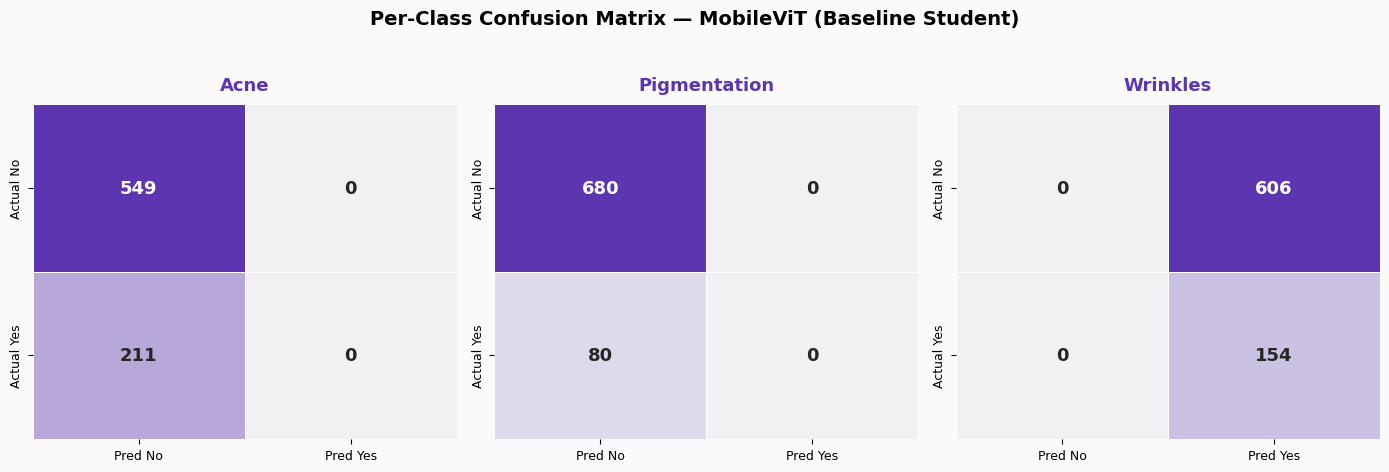

✅ Saved to Google Drive


In [ ]:
# ==============================================================================
# CONFUSION MATRIX — MobileViT Baseline Student
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import multilabel_confusion_matrix, classification_report

CLASSES = ["acne", "pigmentation", "wrinkles"]

# --- Load saved weights into student ---
WEIGHTS_PATH = os.path.join(DATA_ROOT, "mobilevit_student_baseline.weights.h5")
student_eval = KDStudentMobileViT(num_classes=NUM_CLASSES, width=1.0, img_size=IMG_SIZE)
_ = student_eval(tf.zeros([1, *IMG_SIZE, 3]), training=False)
student_eval.load_weights(WEIGHTS_PATH)
print("✅ Weights loaded successfully")

# --- Collect predictions ---
y_true_list, logits_list = [], []
for xb, yb in test_ds:
    lg = student_eval(xb, training=False).numpy()
    y_true_list.append(yb.numpy())
    logits_list.append(lg)

y_true = np.concatenate(y_true_list, axis=0).astype(int)
logits = np.concatenate(logits_list, axis=0)
probs  = 1 / (1 + np.exp(-logits))   # sigmoid
y_pred = (probs >= 0.5).astype(int)

# --- Print classification report ---
print("\n=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=CLASSES, zero_division=0))

# --- Plot per-class confusion matrices ---
mcm = multilabel_confusion_matrix(y_true, y_pred)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
fig.patch.set_facecolor('#FAFAFA')
color = '#5E35B1'

for idx, (ax, cls) in enumerate(zip(axes, CLASSES)):
    cmap = sns.light_palette(color, as_cmap=True)
    sns.heatmap(mcm[idx], annot=True, fmt='d', cmap=cmap, ax=ax,
                xticklabels=['Pred No', 'Pred Yes'],
                yticklabels=['Actual No', 'Actual Yes'],
                linewidths=0.5, linecolor='white',
                annot_kws={'size': 13, 'weight': 'bold'}, cbar=False)
    ax.set_title(cls.capitalize(), fontsize=13, fontweight='bold', color=color, pad=10)
    ax.tick_params(axis='both', labelsize=9)

fig.suptitle('Per-Class Confusion Matrix — MobileViT (Baseline Student)',
             fontsize=14, fontweight='bold', y=1.04)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/mobilevit_confusion_matrix.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved to Google Drive")

In [ ]:
# ==============================================================================
# DIAGNOSTIC: is the saved baseline student loading correctly?
# ==============================================================================
import os, json, numpy as np, tensorflow as tf
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, multilabel_confusion_matrix)

# Fixed-order test set (no shuffle) so predictions line up with test_df rows
test_ds_fixed = (tf.data.Dataset.from_tensor_slices(
                    (test_df["filename"].values, test_df[CLASSES].values.astype(np.float32)))
                 .map(parse_function).batch(BATCH_SIZE))

def predict_probs(model):
    ys, ps = [], []
    for xb, yb in test_ds_fixed:
        ys.append(yb.numpy()); ps.append(tf.sigmoid(model(xb, training=False)).numpy())
    return np.concatenate(ys).astype(int), np.concatenate(ps)

def report(name, y_true, y_prob):
    y_pred = (y_prob >= 0.5).astype(int)
    r = {"exact_match_acc": accuracy_score(y_true, y_pred),
         "per_label_acc": float((y_true == y_pred).mean())}
    for avg in ["macro", "micro"]:
        p, rc, f, _ = precision_recall_fscore_support(y_true, y_pred, average=avg, zero_division=0)
        r.update({f"{avg}_P": p, f"{avg}_R": rc, f"{avg}_F1": f,
                  f"{avg}_AUC": roc_auc_score(y_true, y_prob, average=avg)})
    r["confusion [[TN,FP],[FN,TP]]"] = {c: m.tolist() for c, m in
                                        zip(CLASSES, multilabel_confusion_matrix(y_true, y_pred))}
    print(f"\n===== {name} =====\n" + json.dumps(r, indent=2, default=float))

# A) Load from the .weights.h5 file, and check the weights actually changed
m_w = KDStudentMobileViT(num_classes=NUM_CLASSES, width=1.0, img_size=IMG_SIZE)
_ = m_w(tf.zeros([1, *IMG_SIZE, 3]), training=False)
before = [w.numpy().copy() for w in m_w.weights]
m_w.load_weights(os.path.join(DATA_ROOT, "mobilevit_student_baseline.weights.h5"))
changed = sum(not np.array_equal(b, w.numpy()) for b, w in zip(before, m_w.weights))
print(f"Weights changed by loading: {changed} / {len(m_w.weights)}  (should be all or nearly all)")
yt, pw = predict_probs(m_w)
report("Baseline student, loaded from .weights.h5", yt, pw)

# B) Try the .keras checkpoint (best epoch) as a second route
try:
    m_k = tf.keras.models.load_model(
        os.path.join(DATA_ROOT, "mobilevit_student_baseline.keras"), compile=False,
        custom_objects={"KDStudentMobileViT": KDStudentMobileViT, "MobileViTBlock": MobileViTBlock,
                        "InvertedResidual": InvertedResidual, "ConvBNAct": ConvBNAct})
    _, pk = predict_probs(m_k)
    report("Baseline student, loaded from .keras", yt, pk)
except Exception as e:
    print("\n.keras load failed:", repr(e)[:300])

# Sizes and parameter count
print("\nParams:", m_w.count_params())
for f in ["mobilevit_student_baseline.weights.h5", "mobilevit_student_baseline.keras"]:
    p = os.path.join(DATA_ROOT, f)
    print(f, "->", f"{os.path.getsize(p)/1024**2:.2f} MB" if os.path.exists(p) else "missing")

# Save predictions (fixed order) + the test file list
out = os.path.join(DATA_ROOT, "camera_ready_preds"); os.makedirs(out, exist_ok=True)
np.save(f"{out}/baseline_student_y_true.npy", yt)
np.save(f"{out}/baseline_student_y_prob_weightsh5.npy", pw)
test_df[["filename"] + CLASSES].to_csv(f"{out}/test_split_baseline_nb.csv", index=False)
print("Saved to", out)

Weights changed by loading: 72 / 255  (should be all or nearly all)

===== Baseline student, loaded from .weights.h5 =====
{
  "exact_match_acc": 0.2026315789473684,
  "per_label_acc": 0.6065789473684211,
  "macro_P": 0.06754385964912281,
  "macro_R": 0.3333333333333333,
  "macro_F1": 0.11232676878191102,
  "macro_AUC": 0.5189011144339165,
  "micro_P": 0.2026315789473684,
  "micro_R": 0.34606741573033706,
  "micro_F1": 0.2556016597510373,
  "micro_AUC": 0.5508508097847717,
  "confusion [[TN,FP],[FN,TP]]": {
    "acne": [
      [
        549,
        0
      ],
      [
        211,
        0
      ]
    ],
    "pigmentation": [
      [
        680,
        0
      ],
      [
        80,
        0
      ]
    ],
    "wrinkles": [
      [
        0,
        606
      ],
      [
        0,
        154
      ]
    ]
  }
}

.keras load failed: TypeError("<class '__main__.KDStudentMobileViT'> could not be deserialized properly. Please ensure that components that are Python object instances (l

In [ ]:
# ==============================================================================
# RETRAIN baseline student (GPU), evaluate, save, and verify reload — one session
# ==============================================================================
import pandas as pd
assert tf.config.list_physical_devices("GPU"), "Switch the runtime to T4 GPU first"
set_seeds(42)

student = KDStudentMobileViT(num_classes=NUM_CLASSES, width=1.0, img_size=IMG_SIZE)
_ = student(tf.zeros([1, *IMG_SIZE, 3]), training=False)

# Metrics fixed for logit outputs (the original ones were computed on raw logits)
student.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[tf.keras.metrics.BinaryAccuracy(threshold=0.0, name="bin_acc"),  # logit 0 = prob 0.5
             tf.keras.metrics.AUC(multi_label=True, num_labels=NUM_CLASSES,
                                  from_logits=True, name="auc_roc")])

history = student.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=[
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_auc_roc", mode="max", patience=7,
                                     restore_best_weights=True, verbose=1)])

# 1) Training history (for figures)
pd.DataFrame(history.history).to_csv(f"{out}/baseline_student_v2_history.csv", index=False)

# 2) Test-set results + predictions, computed in memory
yt, p = predict_probs(student)
report("Baseline student v2 (in memory)", yt, p)
np.save(f"{out}/baseline_student_v2_y_true.npy", yt)
np.save(f"{out}/baseline_student_v2_y_prob.npy", p)

# 3) Save weights two ways, then prove the file reloads correctly
NEW_W = os.path.join(DATA_ROOT, "mobilevit_student_baseline_v2.weights.h5")
student.save_weights(NEW_W)
np.save(os.path.join(DATA_ROOT, "mobilevit_student_baseline_v2_weightlist.npy"),
        np.array(student.get_weights(), dtype=object), allow_pickle=True)

chk = KDStudentMobileViT(num_classes=NUM_CLASSES, width=1.0, img_size=IMG_SIZE)
_ = chk(tf.zeros([1, *IMG_SIZE, 3]), training=False)
chk.load_weights(NEW_W)
_, p_chk = predict_probs(chk)
print("\n.weights.h5 reload matches in-memory model:", np.allclose(p, p_chk, atol=1e-5))
if not np.allclose(p, p_chk, atol=1e-5):
    chk.set_weights(list(np.load(os.path.join(DATA_ROOT,
                    "mobilevit_student_baseline_v2_weightlist.npy"), allow_pickle=True)))
    _, p_chk = predict_probs(chk)
    print("Weight-list reload matches in-memory model:", np.allclose(p, p_chk, atol=1e-5))

Epoch 1/25
115/115 ━━━━━━━━━━━━━━━━━━━━ 1198s 9s/step - auc_roc: 0.9177 - bin_acc: 0.8892 - loss: 0.2988 - val_auc_roc: 0.5655 - val_bin_acc: 0.6058 - val_loss: 0.7171 - learning_rate: 0.0010
Epoch 2/25
115/115 ━━━━━━━━━━━━━━━━━━━━ 58s 503ms/step - auc_roc: 0.9701 - bin_acc: 0.9424 - loss: 0.1603 - val_auc_roc: 0.6581 - val_bin_acc: 0.8050 - val_loss: 0.5076 - learning_rate: 0.0010
Epoch 3/25
115/115 ━━━━━━━━━━━━━━━━━━━━ 58s 505ms/step - auc_roc: 0.9770 - bin_acc: 0.9522 - loss: 0.1349 - val_auc_roc: 0.7142 - val_bin_acc: 0.6574 - val_loss: 0.6429 - learning_rate: 0.0010
Epoch 4/25
115/115 ━━━━━━━━━━━━━━━━━━━━ 81s 500ms/step - auc_roc: 0.9844 - bin_acc: 0.9621 - loss: 0.1069 - val_auc_roc: 0.8834 - val_bin_acc: 0.7946 - val_loss: 0.5469 - learning_rate: 0.0010
Epoch 5/25
115/115 ━━━━━━━━━━━━━━━━━━━━ 57s 498ms/step - auc_roc: 0.9858 - bin_acc: 0.9640 - loss: 0.1004 - val_auc_roc: 0.9826 - val_bin_acc: 0.9453 - val_loss: 0.1526 - learning_rate: 0.0010
Epoch 6/25
115/115 ━━━━━━━━━━━━━━━━━

In [ ]:
import os, time, numpy as np, tensorflow as tf
F1 = "/content/drive/MyDrive/acne clean pigmentation wrinkles/"
F2 = "/content/drive/MyDrive/skincareapp/acne clean pigmentation wrinkles/"
CANDIDATES = {"baseline_main": F1+"mobilevit_student_baseline.weights.h5",
              "baseline_skincareapp": F2+"mobilevit_student_baseline.weights.h5",
              "uakd_main": F1+"mobilevit_student_uncertKD.weights.h5",
              "uakd_skincareapp": F2+"mobilevit_student_uncertKD.weights.h5"}
for tag, path in CANDIDATES.items():
    if not os.path.exists(path): print(f"\n{tag}: not found"); continue
    m = KDStudentMobileViT(num_classes=NUM_CLASSES, width=1.0, img_size=IMG_SIZE)
    _ = m(tf.zeros([1, *IMG_SIZE, 3]), training=False)
    before = [w.numpy().copy() for w in m.weights]
    m.load_weights(path)
    changed = sum(not np.array_equal(b, w.numpy()) for b, w in zip(before, m.weights))
    print(f"\n{tag}: {os.path.getsize(path)/1024**2:.2f} MB | modified {time.ctime(os.path.getmtime(path))} | changed {changed}/255")
    if changed > 200:
        yt, p = predict_probs(m); report(tag, yt, p)
        np.save(f"{out}/{tag}_y_true.npy", yt); np.save(f"{out}/{tag}_y_prob.npy", p)

# INT8 model on the same test set
TFLITE = F2 + "mobilevit_uakd_int8.tflite"
if os.path.exists(TFLITE):
    it = tf.lite.Interpreter(model_path=TFLITE); it.allocate_tensors()
    i_d, o_d = it.get_input_details()[0], it.get_output_details()[0]
    (si, zi), (so, zo) = i_d["quantization"], o_d["quantization"]
    ys, ps = [], []
    for xb, yb in test_ds_fixed.unbatch().batch(1):
        it.set_tensor(i_d["index"], np.clip(np.round(xb.numpy()/si + zi), -128, 127).astype(np.int8))
        it.invoke()
        ps.append((it.get_tensor(o_d["index"]).astype(np.float32) - zo) * so); ys.append(yb.numpy())
    yq, pq = np.concatenate(ys).astype(int), np.concatenate(ps)
    report("UAKD + INT8 (TFLite)", yq, pq)
    np.save(f"{out}/uakd_int8_y_prob.npy", pq)
else:
    print("\nINT8 file not found at", TFLITE)


baseline_main: 4.72 MB | modified Tue Mar  3 16:48:07 2026 | changed 72/255

baseline_skincareapp: not found

uakd_main: 4.72 MB | modified Tue Feb 24 16:14:36 2026 | changed 255/255

===== uakd_main =====
{
  "exact_match_acc": 0.9802631578947368,
  "per_label_acc": 0.9890350877192983,
  "macro_P": 0.9580955839125774,
  "macro_R": 0.9790284360189574,
  "macro_F1": 0.9680721031703224,
  "macro_AUC": 0.998174802266912,
  "micro_P": 0.9666666666666667,
  "micro_R": 0.9775280898876404,
  "micro_F1": 0.9720670391061452,
  "micro_AUC": 0.9944953004929125,
  "confusion [[TN,FP],[FN,TP]]": {
    "acne": [
      [
        548,
        1
      ],
      [
        8,
        203
      ]
    ],
    "pigmentation": [
      [
        674,
        6
      ],
      [
        2,
        78
      ]
    ],
    "wrinkles": [
      [
        598,
        8
      ],
      [
        0,
        154
      ]
    ]
  }
}

uakd_skincareapp: not found

INT8 file not found at /content/drive/MyDrive/skincareapp/acn

In [ ]:
# ==============================================================================
# INT8 WITHOUT FLEX: same UAKD weights; extract_patches -> space_to_depth (standard op)
# ==============================================================================
UAKD_W = os.path.join(DATA_ROOT, "mobilevit_student_uncertKD.weights.h5")
m = KDStudentMobileViT(num_classes=NUM_CLASSES, width=1.0, img_size=IMG_SIZE)
_ = m(tf.zeros([1, *IMG_SIZE, 3]), training=False)
m.load_weights(UAKD_W)
_, p_ref = predict_probs(m)                                  # original operation

_orig_call = MobileViTBlock.call
def s2d_call(self, x, training=False):
    x_local = self.local1(x, training=training)
    x_local = self.local2(x_local, training=training)
    H, W = x_local.shape[1], x_local.shape[2]
    hh, ww = H // self.ph, W // self.pw
    patches = tf.nn.space_to_depth(x_local[:, :hh*self.ph, :ww*self.pw, :], self.ph)
    b = tf.shape(patches)[0]
    tokens = self.tok_proj(tf.reshape(patches, [b, hh*ww, self.ph*self.pw*self.dim]))
    for i in range(self.depth):
        y = self.ln1[i](tokens); y = self.mha[i](y, y, training=training); tokens = tokens + y
        y = self.ln2[i](tokens); y = self.ffn1[i](y); y = self.ffn2[i](y); tokens = tokens + y
    tokens = self.tok_unproj(tokens)
    tokens = tf.reshape(tokens, [b, hh, ww, self.ph, self.pw, self.dim])
    tokens = tf.transpose(tokens, [0, 1, 3, 2, 4, 5])
    x_global = tf.reshape(tokens, [b, hh*self.ph, ww*self.pw, self.dim])
    x_global = tf.image.resize(x_global, [H, W])
    return self.fuse(tf.concat([x, x_global], axis=-1), training=training)

MobileViTBlock.call = s2d_call
_, p_s2d = predict_probs(m)                                  # swapped operation
diff = np.abs(p_ref - p_s2d).max()
print(f"FP32 check, max prediction difference: {diff:.2e}  (must be ~1e-6 or smaller)")
assert diff < 1e-4, "Swap changed the model's output - stop and send me this message"

calib = tf.data.Dataset.from_tensor_slices(val_df["filename"].values[:320]).map(decode_and_resize)
def rep_data():
    for img in calib:
        yield [tf.expand_dims(img, 0)]
@tf.function(input_signature=[tf.TensorSpec([1, 224, 224, 3], tf.float32)])
def serve(x):
    return tf.sigmoid(m(x, training=False))

def convert(ops):
    c = tf.lite.TFLiteConverter.from_concrete_functions([serve.get_concrete_function()], m)
    c.optimizations = [tf.lite.Optimize.DEFAULT]
    c.representative_dataset = rep_data
    c.target_spec.supported_ops = ops
    c.inference_input_type = tf.int8
    c.inference_output_type = tf.int8
    return c.convert()
try:
    tfl = convert([tf.lite.OpsSet.TFLITE_BUILTINS_INT8]); mode = "full INT8, standard ops only"
except Exception as e:
    print("Full-INT8 conversion failed, allowing float fallback:", str(e)[:200])
    tfl = convert([tf.lite.OpsSet.TFLITE_BUILTINS_INT8, tf.lite.OpsSet.TFLITE_BUILTINS]); mode = "INT8 + float fallback, standard ops only"
MobileViTBlock.call = _orig_call

TFLITE = os.path.join(DATA_ROOT, "mobilevit_uakd_int8_noflex.tflite")
with open(TFLITE, "wb") as f:
    f.write(tfl)
print(f"Saved {TFLITE}  ({os.path.getsize(TFLITE)/1024**2:.2f} MB)  [{mode}]")

it = tf.lite.Interpreter(model_path=TFLITE); it.allocate_tensors()
i_d, o_d = it.get_input_details()[0], it.get_output_details()[0]
(si, zi), (so, zo) = i_d["quantization"], o_d["quantization"]
ys, ps = [], []
for xb, yb in test_ds_fixed.unbatch().batch(1):
    it.set_tensor(i_d["index"], np.clip(np.round(xb.numpy()/si + zi), -128, 127).astype(np.int8))
    it.invoke()
    ps.append((it.get_tensor(o_d["index"]).astype(np.float32) - zo) * so); ys.append(yb.numpy())
yq, pq = np.concatenate(ys).astype(int), np.concatenate(ps)
report("UAKD + INT8 (no Flex)", yq, pq)
np.save(f"{out}/uakd_int8_noflex_y_prob.npy", pq)

FP32 check, max prediction difference: 0.00e+00  (must be ~1e-6 or smaller)
Full-INT8 conversion failed, allowing float fallback: tensorflow/lite/kernels/read_variable.cc:67 variable != nullptr was not true.Node number 255 (READ_VARIABLE) failed to invoke.


RuntimeError: tensorflow/lite/kernels/read_variable.cc:67 variable != nullptr was not true.Node number 255 (READ_VARIABLE) failed to invoke.

In [ ]:
# ==============================================================================
# INT8 WITHOUT FLEX - conversion retry (weights frozen, as in the original notebook)
# ==============================================================================
MobileViTBlock.call = s2d_call                       # use the standard-op version

@tf.function(input_signature=[tf.TensorSpec([1, 224, 224, 3], tf.float32)])
def serve2(x):
    return tf.sigmoid(m(x, training=False))
cf = serve2.get_concrete_function()

def convert(ops):
    c = tf.lite.TFLiteConverter.from_concrete_functions([cf])   # no model object -> weights frozen
    c.optimizations = [tf.lite.Optimize.DEFAULT]
    c.representative_dataset = rep_data
    c.target_spec.supported_ops = ops
    c.inference_input_type = tf.int8
    c.inference_output_type = tf.int8
    return c.convert()

try:
    tfl = convert([tf.lite.OpsSet.TFLITE_BUILTINS_INT8]); mode = "full INT8, standard ops only"
except Exception as e:
    print("Full-INT8 conversion failed, allowing float fallback:", str(e)[:200])
    tfl = convert([tf.lite.OpsSet.TFLITE_BUILTINS_INT8, tf.lite.OpsSet.TFLITE_BUILTINS]); mode = "INT8 + float fallback, standard ops only"
MobileViTBlock.call = _orig_call                     # restore

TFLITE = os.path.join(DATA_ROOT, "mobilevit_uakd_int8_noflex.tflite")
with open(TFLITE, "wb") as f:
    f.write(tfl)
print(f"Saved {TFLITE}  ({os.path.getsize(TFLITE)/1024**2:.2f} MB)  [{mode}]")

it = tf.lite.Interpreter(model_path=TFLITE); it.allocate_tensors()
i_d, o_d = it.get_input_details()[0], it.get_output_details()[0]
(si, zi), (so, zo) = i_d["quantization"], o_d["quantization"]
ys, ps = [], []
for xb, yb in test_ds_fixed.unbatch().batch(1):
    it.set_tensor(i_d["index"], np.clip(np.round(xb.numpy()/si + zi), -128, 127).astype(np.int8))
    it.invoke()
    ps.append((it.get_tensor(o_d["index"]).astype(np.float32) - zo) * so); ys.append(yb.numpy())
yq, pq = np.concatenate(ys).astype(int), np.concatenate(ps)
report("UAKD + INT8 (no Flex)", yq, pq)
np.save(f"{out}/uakd_int8_noflex_y_prob.npy", pq)

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Saved /content/drive/MyDrive/acne clean pigmentation wrinkles/mobilevit_uakd_int8_noflex.tflite  (1.37 MB)  [full INT8, standard ops only]


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)



===== UAKD + INT8 (no Flex) =====
{
  "exact_match_acc": 0.9592105263157895,
  "per_label_acc": 0.9793859649122807,
  "macro_P": 0.9270921802493755,
  "macro_R": 0.9633688783570301,
  "macro_F1": 0.9436217708649615,
  "macro_AUC": 0.9878402375391149,
  "micro_P": 0.9307359307359307,
  "micro_R": 0.9662921348314607,
  "micro_F1": 0.948180815876516,
  "micro_AUC": 0.9859523007684536,
  "confusion [[TN,FP],[FN,TP]]": {
    "acne": [
      [
        546,
        3
      ],
      [
        10,
        201
      ]
    ],
    "pigmentation": [
      [
        674,
        6
      ],
      [
        5,
        75
      ]
    ],
    "wrinkles": [
      [
        583,
        23
      ],
      [
        0,
        154
      ]
    ]
  }
}


In [ ]:
# ==============================================================================
# UAKD COMPARISON: v2 baseline + 10 epochs  [labels only | plain KD | UAKD]
# ==============================================================================
TEACHER_PATH = os.path.join(DATA_ROOT, "efficientnetv2s_tuned_best.keras")
V2_W = os.path.join(DATA_ROOT, "mobilevit_student_baseline_v2.weights.h5")
T, ALPHA, EPOCHS_FT = 4.0, 0.6, 10

teacher = tf.keras.models.load_model(TEACHER_PATH, compile=False)
teacher.trainable = False

def conf_weight(tp, eps=1e-7):                      # exactly as in the UAKD notebook
    p = tf.clip_by_value(tp, eps, 1.0 - eps)
    H = (-p*tf.math.log(p) - (1-p)*tf.math.log(1-p)) / tf.math.log(2.0)
    return 1.0 - tf.reduce_mean(H, axis=1)

class FineTune(tf.keras.Model):
    def __init__(self, student, teacher, mode):
        super().__init__()
        self.s, self.t, self.mode = student, teacher, mode
        self.ce  = tf.keras.losses.BinaryCrossentropy(from_logits=True)
        self.bce = tf.keras.losses.BinaryCrossentropy(reduction="none")
        self.tracker = tf.keras.metrics.Mean(name="loss")
    @property
    def metrics(self): return [self.tracker]
    def train_step(self, data):
        x, y = data
        if self.mode != "labels_only":
            tp = tf.clip_by_value(self.t(x, training=False), 1e-7, 1 - 1e-7)
            tl = tf.math.log(tp / (1 - tp))
        with tf.GradientTape() as tape:
            sl = self.s(x, training=True)
            ce = self.ce(y, sl)
            if self.mode == "labels_only":
                loss = ce
            else:
                kd = self.bce(tf.sigmoid(tl / T), tf.sigmoid(sl / T))
                w = conf_weight(tp) if self.mode == "uakd" else tf.ones_like(kd)
                loss = (1 - ALPHA) * ce + ALPHA * tf.reduce_mean(w * kd) * T**2
        g = tape.gradient(loss, self.s.trainable_variables)
        self.optimizer.apply_gradients(zip(g, self.s.trainable_variables))
        self.tracker.update_state(loss)
        return {"loss": self.tracker.result()}

for mode in [ "uakd"]:
    set_seeds(42)
    s = KDStudentMobileViT(num_classes=NUM_CLASSES, width=1.0, img_size=IMG_SIZE)
    _ = s(tf.zeros([1, *IMG_SIZE, 3]), training=False)
    s.load_weights(V2_W)
    ft = FineTune(s, teacher, mode)
    ft.compile(optimizer=tf.keras.optimizers.Adam(1e-4))
    print(f"\n######## {mode} ########")
    ft.fit(train_ds, epochs=EPOCHS_FT, verbose=1)
    yt, p = predict_probs(s)
    report(f"v2 + 10 epochs [{mode}]", yt, p)
    np.save(f"{out}/v2_{mode}_y_prob.npy", p)
    s.save_weights(os.path.join(DATA_ROOT, f"mobilevit_student_v2_{mode}.weights.h5"))


######## uakd ########
Epoch 1/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 321s 1s/step - loss: 4.2919
Epoch 2/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 64s 559ms/step - loss: 3.8687
Epoch 3/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 63s 549ms/step - loss: 3.7186
Epoch 4/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 82s 548ms/step - loss: 3.6642
Epoch 5/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 65s 563ms/step - loss: 3.6401
Epoch 6/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 63s 543ms/step - loss: 3.6161
Epoch 7/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 63s 549ms/step - loss: 3.6028
Epoch 8/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 81s 538ms/step - loss: 3.6010
Epoch 9/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 63s 544ms/step - loss: 3.5973
Epoch 10/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 82s 546ms/step - loss: 3.5913

===== v2 + 10 epochs [uakd] =====
{
  "exact_match_acc": 0.975,
  "per_label_acc": 0.987280701754386,
  "macro_P": 0.9421568693670874,
  "macro_R": 0.9824480416897479,
  "macro_F1": 0.9606876273854513,
  "macro_AUC": 0.998826797326259,
  "micro_P": 0.9581497797356828,
  "micr

In [ ]:

yt = np.load(f"{out}/baseline_student_v2_y_true.npy")
for mode in ["labels_only", "plain_kd", "uakd"]:
    p = f"{out}/v2_{mode}_y_prob.npy"
    if os.path.exists(p):
        report(f"v2 + 10 epochs [{mode}]", yt, np.load(p))
    else:
        print(f"\n{mode}: predictions file not found")


===== v2 + 10 epochs [labels_only] =====
{
  "exact_match_acc": 0.9815789473684211,
  "per_label_acc": 0.9899122807017544,
  "macro_P": 0.9598818784212043,
  "macro_R": 0.9820377095258612,
  "macro_F1": 0.9698568305545106,
  "macro_AUC": 0.9989503489790552,
  "micro_P": 0.9730941704035875,
  "micro_R": 0.9752808988764045,
  "micro_F1": 0.9741863075196409,
  "micro_AUC": 0.9985806570125217,
  "confusion [[TN,FP],[FN,TP]]": {
    "acne": [
      [
        549,
        0
      ],
      [
        10,
        201
      ]
    ],
    "pigmentation": [
      [
        671,
        9
      ],
      [
        0,
        80
      ]
    ],
    "wrinkles": [
      [
        603,
        3
      ],
      [
        1,
        153
      ]
    ]
  }
}

===== v2 + 10 epochs [plain_kd] =====
{
  "exact_match_acc": 0.9671052631578947,
  "per_label_acc": 0.9837719298245614,
  "macro_P": 0.9329525396864519,
  "macro_R": 0.9778710428591945,
  "macro_F1": 0.9538492960247825,
  "macro_AUC": 0.9969334735312501

In [ ]:
# ==============================================================================
# UAKD vs plain KD with the ENSEMBLE as teacher (precomputed soft labels)
# ==============================================================================
from sklearn.model_selection import train_test_split
T, ALPHA, EPOCHS_FT = 4.0, 0.6, 10
V2_W = os.path.join(DATA_ROOT, "mobilevit_student_baseline_v2.weights.h5")

def conf_weight(tp, eps=1e-7):
    p = tf.clip_by_value(tp, eps, 1.0 - eps)
    H = (-p*tf.math.log(p) - (1-p)*tf.math.log(1-p)) / tf.math.log(2.0)
    return 1.0 - tf.reduce_mean(H, axis=1)

# Map the ensemble soft labels to this notebook's training images by filename
t_all = np.load(os.path.join(DATA_ROOT, "teacher_train_probs.npy")).astype(np.float32)
_df = pd.read_csv(CSV_PATH)
_tv, _ = train_test_split(_df, test_size=0.15, random_state=42, stratify=_df[CLASSES])
_tr, _ = train_test_split(_tv, test_size=0.15, random_state=42, stratify=_tv[CLASSES])
soft = dict(zip(_tr["filename"].astype(str).map(os.path.basename), t_all))
T_TRAIN = np.stack([soft[os.path.basename(f)] for f in train_df["filename"]]).astype(np.float32)
agree = ((T_TRAIN > 0.5) == train_df[CLASSES].values.astype(bool)).mean()
print("Alignment check (must be > 0.97):", round(float(agree), 4)); assert agree > 0.97

ens_ds = (tf.data.Dataset.from_tensor_slices(
              (train_df["filename"].values, T_TRAIN, train_df[CLASSES].values.astype(np.float32)))
          .shuffle(4096, seed=42, reshuffle_each_iteration=True)
          .map(lambda f, t, y: ((decode_and_resize(f), t), y), num_parallel_calls=tf.data.AUTOTUNE)
          .map(lambda xt, y: ((data_augmentation(xt[0], training=True), xt[1]), y), num_parallel_calls=tf.data.AUTOTUNE)
          .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

class EnsFineTune(tf.keras.Model):
    def __init__(self, student, mode):
        super().__init__()
        self.s, self.mode = student, mode
        self.ce  = tf.keras.losses.BinaryCrossentropy(from_logits=True)
        self.bce = tf.keras.losses.BinaryCrossentropy(reduction="none")
        self.tracker = tf.keras.metrics.Mean(name="loss")
    @property
    def metrics(self): return [self.tracker]
    def train_step(self, data):
        (x, tp), y = data
        tp = tf.clip_by_value(tp, 1e-7, 1 - 1e-7)
        tl = tf.math.log(tp / (1 - tp))
        with tf.GradientTape() as tape:
            sl = self.s(x, training=True)
            kd = self.bce(tf.sigmoid(tl / T), tf.sigmoid(sl / T))
            w = conf_weight(tp) if self.mode == "uakd" else tf.ones_like(kd)
            loss = (1 - ALPHA) * self.ce(y, sl) + ALPHA * tf.reduce_mean(w * kd) * T**2
        g = tape.gradient(loss, self.s.trainable_variables)
        self.optimizer.apply_gradients(zip(g, self.s.trainable_variables))
        self.tracker.update_state(loss)
        return {"loss": self.tracker.result()}

for mode in ["plain_kd", "uakd"]:
    tag = f"v2_ens_{mode}"
    set_seeds(42)
    s = KDStudentMobileViT(num_classes=NUM_CLASSES, width=1.0, img_size=IMG_SIZE)
    _ = s(tf.zeros([1, *IMG_SIZE, 3]), training=False)
    s.load_weights(V2_W)
    ft = EnsFineTune(s, mode)
    ft.compile(optimizer=tf.keras.optimizers.Adam(1e-4))
    print(f"\n######## {tag} ########")
    ft.fit(ens_ds, epochs=EPOCHS_FT, verbose=1)
    yt, p = predict_probs(s)
    np.save(f"{out}/{tag}_y_prob.npy", p)
    s.save_weights(os.path.join(DATA_ROOT, f"mobilevit_student_{tag}.weights.h5"))
    report(f"v2 + 10 epochs [{tag}]", yt, p)

Alignment check (must be > 0.97): 0.9995

######## v2_ens_plain_kd ########
Epoch 1/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 137s 706ms/step - loss: 6.8167
Epoch 2/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 52s 449ms/step - loss: 6.2361
Epoch 3/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 57s 490ms/step - loss: 6.0722
Epoch 4/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 82s 500ms/step - loss: 6.0148
Epoch 5/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 56s 488ms/step - loss: 5.9973
Epoch 6/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 59s 510ms/step - loss: 5.9813
Epoch 7/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 57s 493ms/step - loss: 5.9742
Epoch 8/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 80s 480ms/step - loss: 5.9772
Epoch 9/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 56s 483ms/step - loss: 5.9684
Epoch 10/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 57s 493ms/step - loss: 5.9687

===== v2 + 10 epochs [v2_ens_plain_kd] =====
{
  "exact_match_acc": 0.9789473684210527,
  "per_label_acc": 0.9899122807017544,
  "macro_P": 0.9583522802782957,
  "macro_R": 0.9800234915163825,
  "macro_F1": 0.968767919152

Acne          -> acne_630.jpg
Pigmentation  -> pigmentation_0001.jpg
Wrinkles      -> wrinkle_582.jpg
Acne          -> acne_1403.jpg


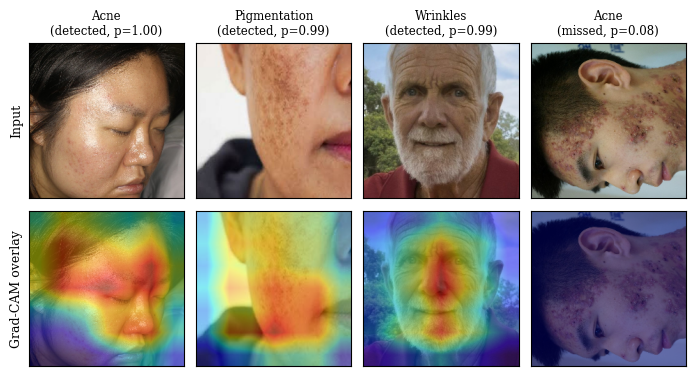

Saved to /content/drive/MyDrive/acne clean pigmentation wrinkles/camera_ready_preds


In [ ]:
# ==============================================================================
# Grad-CAM gallery from the UAKD student (one per condition + one missed case)
# ==============================================================================
import matplotlib.pyplot as plt
m = KDStudentMobileViT(num_classes=NUM_CLASSES, width=1.0, img_size=IMG_SIZE)
_ = m(tf.zeros([1, *IMG_SIZE, 3]), training=False)
m.load_weights(os.path.join(DATA_ROOT, "mobilevit_student_uncertKD.weights.h5"))
yt, P = predict_probs(m); pred = (P >= 0.5).astype(int)
files = test_df["filename"].values

def gradcam(img, c):
    with tf.GradientTape() as tape:
        logits, feats = m(img[None], training=False, return_features=True)
        score = logits[0, c]
    g = tape.gradient(score, feats)[0]
    cam = tf.nn.relu(tf.reduce_sum(feats[0] * tf.reduce_mean(g, axis=(0, 1)), -1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return tf.image.resize(cam[..., None], IMG_SIZE).numpy()[..., 0]

picks = []
for c, name in enumerate(CLASSES):   # first correct detection per class, in test-set order
    i = next(i for i in range(len(yt)) if yt[i, c] == 1 and pred[i, c] == 1)
    picks.append((i, c, f"{name.capitalize()}\n(detected, p={P[i, c]:.2f})"))
i, c = next((i, c) for i in range(len(yt)) for c in range(3) if yt[i, c] == 1 and pred[i, c] == 0)
picks.append((i, c, f"{CLASSES[c].capitalize()}\n(missed, p={P[i, c]:.2f})"))

plt.rcParams.update({"font.family": "serif", "font.size": 8})
fig, ax = plt.subplots(2, 4, figsize=(7.0, 3.9))
for k, (i, c, title) in enumerate(picks):
    img = decode_and_resize(files[i]).numpy()
    ax[0, k].imshow(img); ax[0, k].set_title(title, fontsize=8.5)
    ax[1, k].imshow(img); ax[1, k].imshow(gradcam(img, c), cmap="jet", alpha=0.45)
    for a in (ax[0, k], ax[1, k]): a.set_xticks([]); a.set_yticks([])
    print(f"{title.splitlines()[0]:13s} -> {os.path.basename(files[i])}")
ax[0, 0].set_ylabel("Input", fontsize=9); ax[1, 0].set_ylabel("Grad-CAM overlay", fontsize=9)
plt.tight_layout()
plt.savefig(f"{out}/fig_gradcam_gallery.pdf", bbox_inches="tight")
plt.savefig(f"{out}/fig_gradcam_gallery.png", dpi=300, bbox_inches="tight")
plt.show(); print("Saved to", out)